# Inter IIT Tech Meet 15.0 Selection Bootcamp

## Task 1

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import copy

In [2]:
data=pd.read_csv('data/labels.csv')

In [3]:
data

,index,noisy_label,synthetic_label,clean_label
0,0,4,6,6
1,1,9,6,9
2,2,0,9,9
3,3,5,4,4
4,4,1,1,1
...,...,...,...,...
49995,49995,2,2,2
49996,49996,1,6,6
49997,49997,9,9,9
49998,49998,1,6,1


In [4]:
is_wrong=(data['noisy_label']!=data['clean_label']).sum()

In [5]:
is_wrong

np.int64(20104)

Noise rate

In [6]:
print(f"Training Examples: 50000 \n Wrong Labels:{is_wrong} \n Noise Rate: {is_wrong/500}%")

Training Examples: 50000 
 Wrong Labels:20104 
 Noise Rate: 40.208%


Confusion Matrix

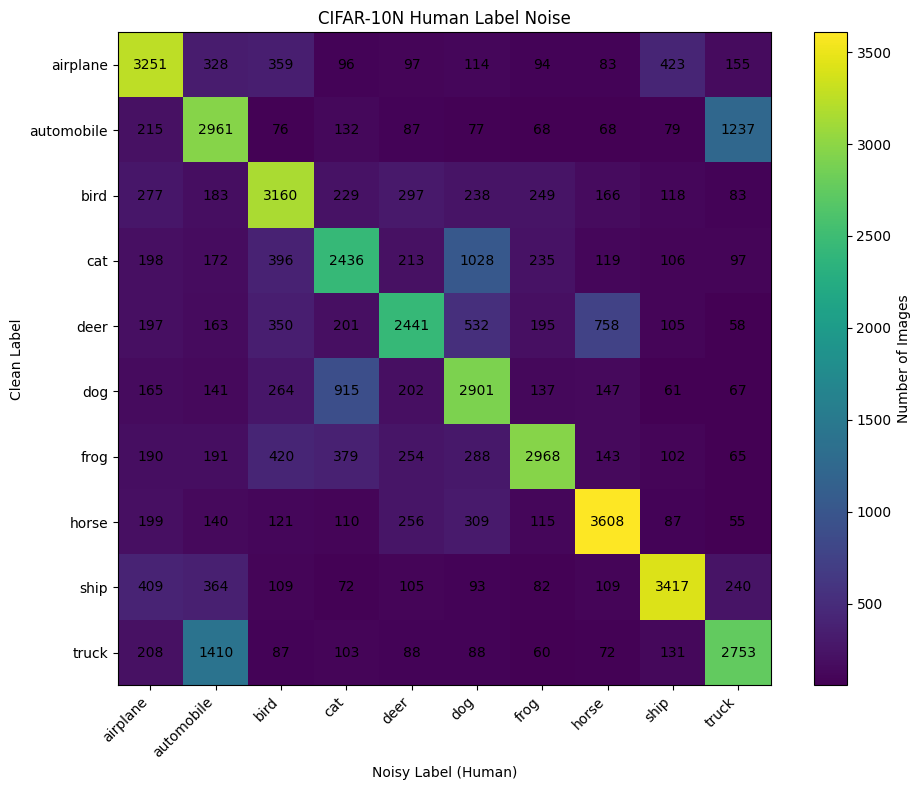

In [7]:
# -----------------------------
# 3. Create the 10x10 confusion matrix
# -----------------------------
# Rows    = clean labels
# Columns = noisy labels

confusion_matrix = np.zeros((10, 10), dtype=int)

for _, row in data.iterrows():
    clean = int(row["clean_label"])
    noisy = int(row["noisy_label"])

    confusion_matrix[clean, noisy] += 1

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

# -----------------------------
# 6. Plot the confusion matrix
# -----------------------------
plt.figure(figsize=(10, 8))

plt.imshow(confusion_matrix)

plt.title("CIFAR-10N Human Label Noise")
plt.xlabel("Noisy Label (Human)")
plt.ylabel("Clean Label")

plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)

# Add numbers to each cell
for i in range(10):
    for j in range(10):
        plt.text(
            j,
            i,
            confusion_matrix[i, j],
            ha="center",
            va="center"
        )

plt.colorbar(label="Number of Images")
plt.tight_layout()
plt.show()

In [8]:
import torch
import torch.nn as nn
from model import ResNet18
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
import torch.optim as optim
import os

In [9]:
os.makedirs("checkpoints", exist_ok=True)
os.makedirs("predictions", exist_ok=True)

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
torch.backends.cudnn.benchmark = True

Using device: cuda


In [11]:
EPOCHS=40

In [12]:
images = np.load("data/train_images.npy")
test_images = np.load("data/test_images.npy")

train_idx = np.loadtxt("data/train_idx.txt", dtype=np.int64)
val_idx = np.loadtxt("data/val_idx.txt", dtype=np.int64)

# Use index as the key, not as an assumption about CSV row order.
data = data.set_index("index")

# Make sure every requested image has a corresponding label.
assert len(train_idx) == 45000, "Expected 45,000 training indices"
assert len(val_idx) == 5000, "Expected 5,000 validation indices"
assert len(test_images) == 10000, "Expected 10,000 test images"

assert data.index.is_unique, "Duplicate indices in labels.csv"
assert np.all(np.isin(train_idx, data.index))
assert np.all(np.isin(val_idx, data.index))

# Task 1 reference model:
train_labels = data.loc[train_idx, "clean_label"].to_numpy(
    dtype=np.int64
)

val_labels = data.loc[val_idx, "clean_label"].to_numpy(
    dtype=np.int64
)

print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Test images:", len(test_images))
print("Image shape:", images.shape)

Training images: 45000
Validation images: 5000
Test images: 10000
Image shape: (50000, 32, 32, 3)


In [13]:
# Standard CIFAR-10 channel statistics.
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# No random augmentation during validation or testing.
eval_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

In [14]:
class CIFARProvidedDataset(Dataset):
    def __init__(self, images, indices, labels=None, transform=None):
        self.images = images
        self.indices = np.asarray(indices, dtype=np.int64)
        self.labels = labels
        self.transform = transform

        if self.labels is not None:
            assert len(self.indices) == len(self.labels)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        image_id = int(self.indices[position])
        image = self.images[image_id]

        if self.transform is not None:
            image = self.transform(image)

        if self.labels is None:
            return image, image_id

        label = int(self.labels[position])
        return image, label


train_dataset = CIFARProvidedDataset(
    images=images,
    indices=train_idx,
    labels=train_labels,
    transform=train_transform,
)

val_dataset = CIFARProvidedDataset(
    images=images,
    indices=val_idx,
    labels=val_labels,
    transform=eval_transform,
)

test_dataset = CIFARProvidedDataset(
    images=test_images,
    indices=np.arange(len(test_images)),
    labels=None,
    transform=eval_transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=True,
    num_workers=10,
    pin_memory=True,
    persistent_workers=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=6,
    pin_memory=True,
    persistent_workers=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=6,
    pin_memory=(device.type == "cuda"),
)

In [15]:
clean_model=ResNet18(num_classes=10).to(device)
torch.compile(clean_model)

OptimizedModule(
  (_orig_mod): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (shortcut): Sequential()
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), 

In [16]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.SGD(clean_model.parameters(),
                     lr=0.1,
                     momentum=0.9,
                    weight_decay=5e-4)
scheduler=optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=60)
scaler=torch.amp.GradScaler('cuda')

In [17]:
def train_one_epoch(model, loader):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for inputs, targets in loader:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            logits = model(inputs)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == targets).sum().item()
        total_examples += batch_size

    return (
        total_loss / total_examples,
        100.0 * total_correct / total_examples,
    )

In [18]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for inputs, targets in loader:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        logits = model(inputs)
        loss = criterion(logits, targets)

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == targets).sum().item()
        total_examples += batch_size

    return (
        total_loss / total_examples,
        100.0 * total_correct / total_examples,
    )

In [19]:
history = []

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(clean_model, train_loader)
    val_loss, val_noisy_acc = evaluate(clean_model, val_loader)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_noisy_acc,
        "learning_rate": current_lr,
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] "
        f"lr={current_lr:.5f} "
        f"train_loss={train_loss:.4f} "
        f"train_acc={train_acc:.2f}% "
        f"val_loss={val_loss:.4f} "
        f"val_noisy_acc={val_noisy_acc:.2f}%"
    )

    scheduler.step()

# Save history for analysis.
pd.DataFrame(history).to_csv(
    "checkpoints/t1_clean_ref_history.csv",
    index=False,
)

# Save the final-epoch model, as required for Task 1.
torch.save(
    {
        "epoch": EPOCHS,
        "model_state_dict": clean_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
    },
    "checkpoints/t1_clean_ref_final.pt",
)

print("Saved final-epoch checkpoint.")

Epoch [01/40] lr=0.10000 train_loss=2.1909 train_acc=25.60% val_loss=1.9511 val_noisy_acc=30.36%
Epoch [02/40] lr=0.09993 train_loss=1.5888 train_acc=40.50% val_loss=1.5160 val_noisy_acc=44.64%
Epoch [03/40] lr=0.09973 train_loss=1.3847 train_acc=49.17% val_loss=1.3238 val_noisy_acc=50.80%
Epoch [04/40] lr=0.09938 train_loss=1.2081 train_acc=56.20% val_loss=1.2125 val_noisy_acc=57.02%
Epoch [05/40] lr=0.09891 train_loss=1.0726 train_acc=61.13% val_loss=1.1761 val_noisy_acc=59.36%
Epoch [06/40] lr=0.09830 train_loss=0.9459 train_acc=66.19% val_loss=1.0484 val_noisy_acc=63.58%
Epoch [07/40] lr=0.09755 train_loss=0.8542 train_acc=69.84% val_loss=0.9919 val_noisy_acc=66.14%
Epoch [08/40] lr=0.09668 train_loss=0.7332 train_acc=74.04% val_loss=0.8785 val_noisy_acc=70.68%
Epoch [09/40] lr=0.09568 train_loss=0.6662 train_acc=76.52% val_loss=0.7609 val_noisy_acc=73.82%
Epoch [10/40] lr=0.09455 train_loss=0.5993 train_acc=79.05% val_loss=0.6942 val_noisy_acc=75.58%
Epoch [11/40] lr=0.09330 train

In [20]:
@torch.no_grad()
def predict(model, loader):
    model.eval()

    all_ids = []
    all_predictions = []

    for inputs, image_ids in loader:
        inputs = inputs.to(device, non_blocking=True)

        logits = model(inputs)
        predictions = logits.argmax(dim=1).cpu().numpy()

        all_ids.extend(image_ids.numpy().tolist())
        all_predictions.extend(predictions.tolist())

    return np.asarray(all_ids), np.asarray(all_predictions)



In [21]:
test_ids, test_predictions = predict(clean_model, test_loader)

# Ensure predictions are in the required ID order.
order = np.argsort(test_ids)
test_ids = test_ids[order]
test_predictions = test_predictions[order]

assert len(test_predictions) == 10000
assert np.array_equal(test_ids, np.arange(10000))
assert np.all((test_predictions >= 0) & (test_predictions < 10))

pd.DataFrame({
    "id": test_ids,
    "pred": test_predictions,
}).to_csv(
    "predictions/t1_clean_ref.csv",
    index=False,
)

print("Saved predictions/t1_clean_ref.csv")
print("Training completed successfully.")

Saved predictions/t1_clean_ref.csv
Training completed successfully.


Model on Noisy Labels

In [22]:
noisy_labels_val=data.loc[val_idx, "noisy_label"].to_numpy(
    dtype=np.int64
)
noisy_labels_train=data.loc[train_idx, "noisy_label"].to_numpy(
    dtype=np.int64
)
noisy_train_dataset = CIFARProvidedDataset(
    images=images,
    indices=train_idx,
    labels=noisy_labels_train,
    transform=train_transform,
)

noisy_val_dataset = CIFARProvidedDataset(
    images=images,
    indices=val_idx,
    labels=noisy_labels_val,
    transform=eval_transform,
)

noisy_train_loader = DataLoader(
    noisy_train_dataset,
    batch_size=1024,
    shuffle=True,
    num_workers=10,
    pin_memory=True,
    persistent_workers=True,
)

noisy_val_loader = DataLoader(
    noisy_val_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=6,
    pin_memory=True,
    persistent_workers=True,
)

In [23]:
noisy_model=ResNet18(num_classes=10).to(device)
torch.compile(noisy_model)

OptimizedModule(
  (_orig_mod): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (shortcut): Sequential()
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), 

In [24]:
#Reset everything
criterion=nn.CrossEntropyLoss()
optimizer=optim.SGD(noisy_model.parameters(),
                     lr=0.1,
                     momentum=0.9,
                    weight_decay=5e-4)
scheduler=optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=60)
scaler=torch.amp.GradScaler('cuda')

In [25]:
history = []

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(noisy_model, noisy_train_loader)
    val_loss, val_noisy_acc = evaluate(noisy_model, noisy_val_loader)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_noisy_loss": val_loss,
        "val_noisy_acc": val_noisy_acc,
        "learning_rate": current_lr,
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] "
        f"lr={current_lr:.5f} "
        f"train_loss={train_loss:.4f} "
        f"train_acc={train_acc:.2f}% "
        f"val_loss={val_loss:.4f} "
        f"val_noisy_acc={val_noisy_acc:.2f}%"
    )

    scheduler.step()

# Save history for analysis.
pd.DataFrame(history).to_csv(
    "checkpoints/t1_noisy_ref_history.csv",
    index=False,
)

# Save the final-epoch model, as required for Task 1.
torch.save(
    {
        "epoch": EPOCHS,
        "model_state_dict": noisy_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
    },
    "checkpoints/t1_noisy_ref_final.pt",
)

print("Saved final-epoch checkpoint.")

Epoch [01/40] lr=0.10000 train_loss=2.8120 train_acc=15.15% val_loss=2.3757 val_noisy_acc=19.08%
Epoch [02/40] lr=0.09993 train_loss=2.0572 train_acc=23.17% val_loss=2.0054 val_noisy_acc=26.70%
Epoch [03/40] lr=0.09973 train_loss=1.9736 train_acc=27.78% val_loss=1.9605 val_noisy_acc=28.30%
Epoch [04/40] lr=0.09938 train_loss=1.9238 train_acc=29.89% val_loss=1.9279 val_noisy_acc=31.26%
Epoch [05/40] lr=0.09891 train_loss=1.8808 train_acc=32.80% val_loss=1.8861 val_noisy_acc=32.30%
Epoch [06/40] lr=0.09830 train_loss=1.8539 train_acc=34.16% val_loss=1.8807 val_noisy_acc=32.46%
Epoch [07/40] lr=0.09755 train_loss=1.8092 train_acc=36.68% val_loss=1.8380 val_noisy_acc=35.34%
Epoch [08/40] lr=0.09668 train_loss=1.7775 train_acc=38.57% val_loss=1.7693 val_noisy_acc=39.22%
Epoch [09/40] lr=0.09568 train_loss=1.7455 train_acc=40.00% val_loss=1.7704 val_noisy_acc=38.76%
Epoch [10/40] lr=0.09455 train_loss=1.7162 train_acc=41.34% val_loss=1.7403 val_noisy_acc=41.12%
Epoch [11/40] lr=0.09330 train

In [26]:
test_ids, test_predictions = predict(noisy_model, test_loader)

# Ensure predictions are in the required ID order.
order = np.argsort(test_ids)
test_ids = test_ids[order]
test_predictions = test_predictions[order]

assert len(test_predictions) == 10000
assert np.array_equal(test_ids, np.arange(10000))
assert np.all((test_predictions >= 0) & (test_predictions < 10))

pd.DataFrame({
    "id": test_ids,
    "pred": test_predictions,
}).to_csv(
    "predictions/t1_noisy_ce.csv",
    index=False,
)
 
print("Saved predictions/t1_noisy_ce.csv")
print("Training completed successfully.")

Saved predictions/t1_noisy_ce.csv
Training completed successfully.


## Task 2

In [27]:
model3=ResNet18(num_classes=10).to(device)
torch.compile(model3)

OptimizedModule(
  (_orig_mod): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (shortcut): Sequential()
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), 

In [28]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.SGD(model3.parameters(),
                     lr=0.1,
                     momentum=0.9,
                    weight_decay=5e-4)
scheduler=optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=60)
scaler=torch.amp.GradScaler('cuda')

In [ ]:
import copy
history = []
best_val_noisy_acc = -1.0
best_epoch = None

for epoch in range(1, EPOCHS + 1):
    train_loss, noisy_train_acc = train_one_epoch(model3, noisy_train_loader)
    val_loss, val_noisy_acc = evaluate(model3, noisy_val_loader)
    _,clean_train_acc=evaluate(model3, train_loader)
    _,clean_val_acc=evaluate(model3, val_loader)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_acc_correct": clean_train_acc,
        "train_accuracy_mislabeled": noisy_train_acc,
        "val_acc_noisy": val_noisy_acc,
        "val_acc_clean": clean_val_acc,
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] "
        f"lr={current_lr:.5f} "
        f"train_loss={train_loss:.4f} "
        f"train_acc={noisy_train_acc:.2f}% "
        f"val_loss={val_loss:.4f} "
        f"val_noisy_acc={val_noisy_acc:.2f}%"
    )

    if val_noisy_acc > best_val_noisy_acc:
        best_val_noisy_acc = val_noisy_acc
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": copy.deepcopy(model3.state_dict()),
                "val_acc_noisy": val_noisy_acc,
            },
            "checkpoints/t2_noisy_early_stop.pt",
        )

    scheduler.step()

# Save history for analysis.
pd.DataFrame(history).to_csv(
    "predictions/t2_dynamics.csv",
    index=False,
)

# Save the final-epoch model, as required for Task 1.
torch.save(
    {
        "epoch": EPOCHS,
        "model_state_dict": model3.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
    },
    "checkpoints/t2_noisy_final.pt",
)

print("\nBest early-stopping epoch:", best_epoch)
print("Best noisy validation accuracy:", f"{best_val_noisy_acc:.2f}%")

Epoch [01/40] lr=0.10000 train_loss=2.4631 train_acc=18.19% val_loss=2.1046 val_noisy_acc=23.96%
Epoch [02/40] lr=0.09993 train_loss=2.0128 train_acc=26.18% val_loss=1.9640 val_noisy_acc=29.28%
Epoch [03/40] lr=0.09973 train_loss=1.9495 train_acc=29.90% val_loss=1.9333 val_noisy_acc=30.40%
Epoch [04/40] lr=0.09938 train_loss=1.8861 train_acc=32.97% val_loss=1.8681 val_noisy_acc=34.72%
Epoch [05/40] lr=0.09891 train_loss=1.8477 train_acc=34.95% val_loss=1.9003 val_noisy_acc=32.62%
Epoch [06/40] lr=0.09830 train_loss=1.8092 train_acc=36.98% val_loss=1.8016 val_noisy_acc=36.70%
Epoch [07/40] lr=0.09755 train_loss=1.7650 train_acc=38.78% val_loss=1.7936 val_noisy_acc=38.58%
Epoch [08/40] lr=0.09668 train_loss=1.7363 train_acc=40.63% val_loss=1.7451 val_noisy_acc=40.76%
Epoch [09/40] lr=0.09568 train_loss=1.7062 train_acc=42.04% val_loss=1.7363 val_noisy_acc=40.84%
Epoch [10/40] lr=0.09455 train_loss=1.6690 train_acc=43.80% val_loss=1.7000 val_noisy_acc=44.04%
Epoch [11/40] lr=0.09330 train

In [30]:
#test accuracy
early_checkpoint = torch.load(
    "checkpoints/t2_noisy_early_stop.pt",
    map_location=device,
    weights_only=True,
)

model3.load_state_dict(early_checkpoint["model_state_dict"])

test_ids, test_preds = predict(model3, test_loader)

order = np.argsort(test_ids)
test_ids = test_ids[order]
test_preds = test_preds[order]

assert len(test_ids) == 10000
assert np.array_equal(test_ids, np.arange(10000))
assert np.all((test_preds >= 0) & (test_preds < 10))

pd.DataFrame({
    "id": test_ids,
    "pred": test_preds,
}).to_csv(
    "predictions/t2_early_stop.csv",
    index=False,
)

print("Saved predictions/t2_early_stop.csv")


Saved predictions/t2_early_stop.csv


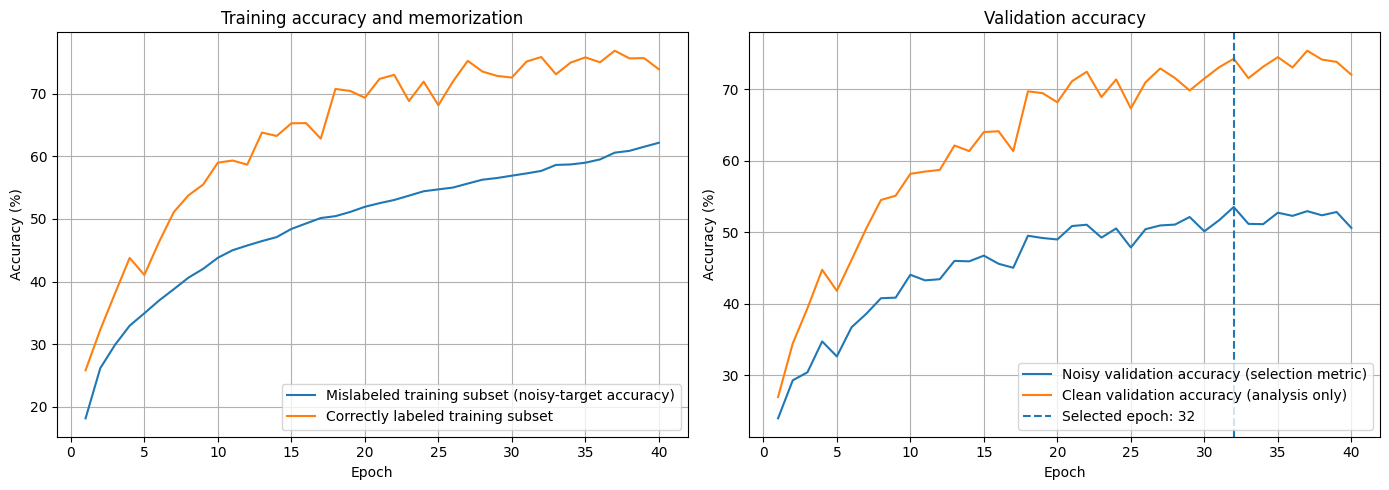

Task 2 complete.


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
history_df=pd.read_csv("checkpoints/t2_dynamics.csv")

axes[0].plot(
    history_df["epoch"],
    history_df["train_accuracy_mislabelled"],
    label="Mislabeled training subset (noisy-target accuracy)",
)
axes[0].plot(
    history_df["epoch"],
    history_df["train_acc_correct"],
    label="Correctly labeled training subset",
)
axes[0].set_title("Training accuracy and memorization")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_df["epoch"],
    history_df["val_acc_noisy"],
    label="Noisy validation accuracy (selection metric)",
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_acc_clean"],
    label="Clean validation accuracy (analysis only)",
)
axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Selected epoch: {best_epoch}",
)
axes[1].set_title("Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()
print("Task 2 complete.")


## Task 3 
Create 5 models for 5 fold out-of-fold predictions

In [32]:
from sklearn.model_selection import StratifiedKFold
os.makedirs("checkpoints/task3", exist_ok=True)
os.makedirs("predictions", exist_ok=True)

In [33]:
N_FOLDS=5
@torch.no_grad()
def score_heldout_images(model, loader, noisy_label_by_id):
    """
    Score held-out images using out-of-fold predictions.

    noise_score = -log(P(noisy label | image))

    Higher score means the model assigns less probability
    to the supplied noisy label, making it more suspicious.
    """
    model.eval()

    scores = {}

    for inputs, image_ids in loader:
        inputs = inputs.to(device, non_blocking=True)

        logits = model(inputs)
        probabilities = torch.softmax(logits, dim=1)

        ids = image_ids.numpy()

        for j, image_id in enumerate(ids):
            noisy_label = int(noisy_label_by_id[int(image_id)])

            p_noisy = probabilities[j, noisy_label].item()

            # Clamp to avoid log(0) from numerical underflow.
            p_noisy = max(p_noisy, 1e-12)

            scores[int(image_id)] = -np.log(p_noisy)

    return scores


In [34]:
# Map original image ID to its noisy label.
noisy_label_by_id = {
    int(image_id): int(label)
    for image_id, label in zip(train_idx, noisy_labels_train)
}

# 6. Five-fold out-of-fold scoring

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
)

all_scores = {}
fold_summaries = []

for fold, (fit_positions, heldout_positions) in enumerate(
    skf.split(train_idx, noisy_labels_train), start=1
):
    print("\n" + "=" * 65)
    print(f"FOLD {fold}/{N_FOLDS}")
    print("=" * 65)

    # Positions refer to the arrays ordered by train_idx.
    fit_idx = train_idx[fit_positions]
    heldout_idx = train_idx[heldout_positions]

    fit_labels = noisy_labels_train[fit_positions]

    print("Fit images:", len(fit_idx))
    print("Held-out images:", len(heldout_idx))

    fit_dataset = CIFARProvidedDataset(
        images=images,
        indices=fit_idx,
        labels=fit_labels,
        transform=train_transform,
    )

    fit_loader = DataLoader(
        fit_dataset,
        batch_size=1024,
        shuffle=True,
        num_workers=10,
        pin_memory=(device.type == "cuda"),
    )

    heldout_dataset = CIFARProvidedDataset(
        images=images,
        indices=heldout_idx,
        transform=eval_transform,
    )

    heldout_loader = DataLoader(
        heldout_dataset,
        batch_size=512,
        shuffle=False,
        num_workers=6,
        pin_memory=(device.type == "cuda"),
    )

    # A new model from scratch for each fold.
    model = ResNet18(num_classes=10).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        model.parameters(),
        lr=0.1,
        momentum=0.9,
        weight_decay=5e-4,
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS,
    )
    
    # Select checkpoint using noisy validation accuracy only.
    best_val_acc = -1.0
    best_epoch = None
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        train_loss,train_acc = train_one_epoch(
            model, fit_loader
        )

        _,val_acc = evaluate(model, noisy_val_loader)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        scheduler.step()

        print(
            f"Fold {fold} | Epoch {epoch:02d}/{EPOCHS} | "
            f"loss={train_loss:.4f} | "
            f"train_accuracy={train_acc:.2f}% |"
            f"noisy_val_acc={val_acc:.2f}% | "
            f"best_epoch={best_epoch}"
        )

    # Restore the best noisy-validation checkpoint.
    model.load_state_dict(best_state)

    checkpoint_path = f"checkpoints/task3/fold_{fold}.pt"

    torch.save(
        {
            "fold": fold,
            "epoch": best_epoch,
            "val_acc_noisy": best_val_acc,
            "model_state_dict": best_state,
        },
        checkpoint_path,
    )

    # Every held-out image is scored by a model that did not
    # train on that image.
    fold_scores = score_heldout_images(
        model, heldout_loader, noisy_label_by_id
    )

    overlap = set(all_scores).intersection(fold_scores)
    assert not overlap, f"Duplicate held-out IDs: {overlap}"

    all_scores.update(fold_scores)

    fold_summaries.append({
        "fold": fold,
        "fit_images": len(fit_idx),
        "heldout_images": len(heldout_idx),
        "best_epoch": best_epoch,
        "best_val_acc_noisy": best_val_acc,
    })

    print(
        f"Fold {fold} complete. "
        f"Best epoch={best_epoch}, "
        f"best noisy validation accuracy={best_val_acc:.2f}%"
    )

    del model, optimizer, scheduler, fit_loader, heldout_loader

    if device.type == "cuda":
        torch.cuda.empty_cache()



FOLD 1/5
Fit images: 36000
Held-out images: 9000
Fold 1 | Epoch 01/40 | loss=2.5648 | train_accuracy=15.68% |noisy_val_acc=17.58% | best_epoch=1
Fold 1 | Epoch 02/40 | loss=2.0570 | train_accuracy=23.81% |noisy_val_acc=26.92% | best_epoch=2
Fold 1 | Epoch 03/40 | loss=1.9811 | train_accuracy=27.85% |noisy_val_acc=29.20% | best_epoch=3
Fold 1 | Epoch 04/40 | loss=1.9263 | train_accuracy=31.04% |noisy_val_acc=30.98% | best_epoch=4
Fold 1 | Epoch 05/40 | loss=1.8654 | train_accuracy=33.94% |noisy_val_acc=34.24% | best_epoch=5
Fold 1 | Epoch 06/40 | loss=1.8354 | train_accuracy=35.89% |noisy_val_acc=35.14% | best_epoch=6
Fold 1 | Epoch 07/40 | loss=1.8036 | train_accuracy=37.39% |noisy_val_acc=36.00% | best_epoch=7
Fold 1 | Epoch 08/40 | loss=1.7761 | train_accuracy=38.70% |noisy_val_acc=39.98% | best_epoch=8
Fold 1 | Epoch 09/40 | loss=1.7490 | train_accuracy=39.68% |noisy_val_acc=39.00% | best_epoch=8
Fold 1 | Epoch 10/40 | loss=1.7205 | train_accuracy=41.27% |noisy_val_acc=36.16% | bes

In [35]:
assert len(all_scores) == 45000, (
    f"Expected 45,000 scores, got {len(all_scores)}"
)

assert set(all_scores.keys()) == set(map(int, train_idx)), (
    "Scores must cover exactly the supplied training indices"
)

scores_df = pd.DataFrame({
    "index": list(all_scores.keys()),
    "score": list(all_scores.values()),
})

# Sort by image index for reproducibility.
scores_df = scores_df.sort_values("index").reset_index(drop=True)

assert scores_df["index"].is_unique
assert scores_df["score"].notna().all()
assert np.isfinite(scores_df["score"]).all()

scores_df.to_csv(
    "predictions/t3_noise_scores.csv",
    index=False,
)

pd.DataFrame(fold_summaries).to_csv(
    "checkpoints/task3/fold_summary.csv",
    index=False,
)

print("\nTask 3 completed.")
print("Number of scored training images:", len(scores_df))
print("Output: predictions/t3_noise_scores.csv")
print("\nScore summary:")
print(scores_df["score"].describe())



Task 3 completed.
Number of scored training images: 45000
Output: predictions/t3_noise_scores.csv

Score summary:
count    45000.000000
mean         1.591764
std          1.308732
min          0.010474
25%          0.529485
50%          1.182218
75%          2.403636
max          9.491525
Name: score, dtype: float64


# Task 4

### Method 1 Label Smoothing

In [36]:
model4=ResNet18(num_classes=10).to(device)
torch.compile(model4)

OptimizedModule(
  (_orig_mod): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (shortcut): Sequential()
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), 

In [37]:
criterion=nn.CrossEntropyLoss(label_smoothing=0.1) # using label smoothing
optimizer=optim.SGD(model4.parameters(),
                     lr=0.1,
                     momentum=0.9,
                    weight_decay=5e-4)
scheduler=optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=60)
scaler=torch.amp.GradScaler('cuda')

In [38]:
history = []
best_val_noisy_acc = -1.0
best_epoch = None

for epoch in range(1, EPOCHS + 1):
    train_loss, noisy_train_acc = train_one_epoch(model4, noisy_train_loader)
    val_loss, val_noisy_acc = evaluate(model4, noisy_val_loader)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_accuracy_mislabelled": noisy_train_acc,
        "val_acc_noisy": val_noisy_acc,
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] "
        f"lr={current_lr:.5f} "
        f"train_loss={train_loss:.4f} "
        f"train_acc={noisy_train_acc:.2f}% "
        f"val_loss={val_loss:.4f} "
        f"val_noisy_acc={val_noisy_acc:.2f}%"
    )

    if val_noisy_acc > best_val_noisy_acc:
        best_val_noisy_acc = val_noisy_acc
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": copy.deepcopy(model4.state_dict()),
                "val_acc_noisy": val_noisy_acc,
            },
            "checkpoints/t4_label_smoothing.pt",
        )

    scheduler.step()

# Save history for analysis.
pd.DataFrame(history).to_csv(
    "checkpoints/t4_logs.csv",
    index=False,
)

print("\nBest early-stopping epoch:", best_epoch)
print("Best noisy validation accuracy:", f"{best_val_noisy_acc:.2f}%")

Epoch [01/40] lr=0.10000 train_loss=3.0113 train_acc=12.61% val_loss=2.3742 val_noisy_acc=14.22%
Epoch [02/40] lr=0.09993 train_loss=2.1809 train_acc=18.99% val_loss=2.1354 val_noisy_acc=21.32%
Epoch [03/40] lr=0.09973 train_loss=2.1051 train_acc=23.21% val_loss=2.0744 val_noisy_acc=24.48%
Epoch [04/40] lr=0.09938 train_loss=2.0632 train_acc=26.34% val_loss=2.0377 val_noisy_acc=28.64%
Epoch [05/40] lr=0.09891 train_loss=2.0342 train_acc=28.62% val_loss=2.0327 val_noisy_acc=27.96%
Epoch [06/40] lr=0.09830 train_loss=2.0078 train_acc=30.00% val_loss=1.9856 val_noisy_acc=31.44%
Epoch [07/40] lr=0.09755 train_loss=1.9755 train_acc=32.15% val_loss=1.9665 val_noisy_acc=32.34%
Epoch [08/40] lr=0.09668 train_loss=1.9548 train_acc=33.68% val_loss=1.9303 val_noisy_acc=34.52%
Epoch [09/40] lr=0.09568 train_loss=1.9280 train_acc=35.25% val_loss=1.9397 val_noisy_acc=35.26%
Epoch [10/40] lr=0.09455 train_loss=1.9103 train_acc=36.34% val_loss=1.9004 val_noisy_acc=38.02%
Epoch [11/40] lr=0.09330 train

In [39]:
#test accuracy
early_checkpoint = torch.load(
    "checkpoints/t4_label_smoothing.pt",
    map_location=device,
    weights_only=True,
)

model4.load_state_dict(early_checkpoint["model_state_dict"])

test_ids, test_preds = predict(model4, test_loader)

order = np.argsort(test_ids)
test_ids = test_ids[order]
test_preds = test_preds[order]

assert len(test_ids) == 10000
assert np.array_equal(test_ids, np.arange(10000))
assert np.all((test_preds >= 0) & (test_preds < 10))

pd.DataFrame({
    "id": test_ids,
    "pred": test_preds,
}).to_csv(
    "predictions/t4_label_smoothing.csv",
    index=False,
)

print("Saved predictions/t4_label_smoothing.csv")


Saved predictions/t4_label_smoothing.csv


### Method 2 Generalized Cross Entropy Loss

In [40]:
model5=ResNet18(num_classes=10).to(device)
torch.compile(model5)

OptimizedModule(
  (_orig_mod): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (shortcut): Sequential()
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), 

In [41]:
GCE_Q = 0.7

def generalized_cross_entropy(logits, targets, q=GCE_Q):
    """
    logits:  (batch_size, num_classes)
    targets: (batch_size,) noisy-label class IDs
    """
    probabilities = nn.functional.softmax(logits, dim=1)
    p_correct_label = probabilities.gather(
        dim=1, index=targets.view(-1, 1)
    ).squeeze(1)

    loss = (1.0 - p_correct_label.pow(q)) / q
    return loss.mean()

In [42]:
optimizer=optim.SGD(model5.parameters(),
                     lr=0.1,
                     momentum=0.9,
                    weight_decay=5e-4)
scheduler=optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=60)
scaler=torch.amp.GradScaler('cuda')

In [43]:
def train_one(model, loader):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for inputs, targets in loader:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda'):
            logits = model(inputs)
            loss = generalized_cross_entropy(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == targets).sum().item()
        total_examples += batch_size

    return (
        total_loss / total_examples,
        100.0 * total_correct / total_examples,
    )

In [44]:
history = []
best_val_noisy_acc = -1.0
best_epoch = None

for epoch in range(1, EPOCHS + 1):
    train_loss, noisy_train_acc = train_one(model5, noisy_train_loader)
    _, val_noisy_acc = evaluate(model5, noisy_val_loader)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_accuracy_mislabelled": noisy_train_acc,
        "val_accuracy_mislabelled": val_noisy_acc,
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] "
        f"lr={current_lr:.5f} "
        f"train_loss={train_loss:.4f} "
        f"train_acc={noisy_train_acc:.2f}% "
        f"val_noisy_acc={val_noisy_acc:.2f}%"
    )

    if val_noisy_acc > best_val_noisy_acc:
        best_val_noisy_acc = val_noisy_acc
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": copy.deepcopy(model5.state_dict()),
                "val_acc_noisy": val_noisy_acc,
            },
            "checkpoints/t4_robust_loss.pt",
        )

    scheduler.step()

# Save history for analysis.
pd.DataFrame(history).to_csv(
    "checkpoints/t4_robust_loss_logs.csv",
    index=False,
) 

print("\nBest early-stopping epoch:", best_epoch)
print("Best noisy validation accuracy:", f"{best_val_noisy_acc:.2f}%")

Epoch [01/40] lr=0.10000 train_loss=1.0146 train_acc=24.29% val_noisy_acc=29.94%
Epoch [02/40] lr=0.09993 train_loss=0.9267 train_acc=32.20% val_noisy_acc=30.92%
Epoch [03/40] lr=0.09973 train_loss=0.8776 train_acc=36.04% val_noisy_acc=36.96%
Epoch [04/40] lr=0.09938 train_loss=0.8419 train_acc=38.82% val_noisy_acc=36.88%
Epoch [05/40] lr=0.09891 train_loss=0.8101 train_acc=41.32% val_noisy_acc=40.60%
Epoch [06/40] lr=0.09830 train_loss=0.7927 train_acc=42.49% val_noisy_acc=39.96%
Epoch [07/40] lr=0.09755 train_loss=0.7705 train_acc=44.10% val_noisy_acc=38.24%
Epoch [08/40] lr=0.09668 train_loss=0.7411 train_acc=45.95% val_noisy_acc=43.20%
Epoch [09/40] lr=0.09568 train_loss=0.7102 train_acc=48.35% val_noisy_acc=46.38%
Epoch [10/40] lr=0.09455 train_loss=0.6902 train_acc=50.01% val_noisy_acc=48.50%
Epoch [11/40] lr=0.09330 train_loss=0.6805 train_acc=50.61% val_noisy_acc=47.92%
Epoch [12/40] lr=0.09193 train_loss=0.6671 train_acc=51.58% val_noisy_acc=44.28%
Epoch [13/40] lr=0.09045 tra

In [45]:
#test accuracy
early_checkpoint = torch.load(
    "checkpoints/t4_robust_loss.pt",
    map_location=device,
    weights_only=True,
)

model5.load_state_dict(early_checkpoint["model_state_dict"])

test_ids, test_preds = predict(model5, test_loader)

order = np.argsort(test_ids)
test_ids = test_ids[order]
test_preds = test_preds[order]

assert len(test_ids) == 10000
assert np.array_equal(test_ids, np.arange(10000))
assert np.all((test_preds >= 0) & (test_preds < 10))

pd.DataFrame({
    "id": test_ids,
    "pred": test_preds,
}).to_csv(
    "predictions/t4_robust_loss.csv",
    index=False,
)

print("Saved predictions/t4_robust_loss.csv")


Saved predictions/t4_robust_loss.csv


GCE performed better than label smoothing

# Task 5

## Training on cross entropy baseline

In [46]:
synthetic_labels_val=data.loc[val_idx, "synthetic_label"].to_numpy(
    dtype=np.int64
)
synthetic_labels_train=data.loc[train_idx, "synthetic_label"].to_numpy(
    dtype=np.int64
)
synthetic_train_dataset = CIFARProvidedDataset(
    images=images,
    indices=train_idx,
    labels=synthetic_labels_train,
    transform=train_transform,
)

synthetic_val_dataset = CIFARProvidedDataset(
    images=images,
    indices=val_idx,
    labels=synthetic_labels_val,
    transform=eval_transform,
)

synthetic_train_loader = DataLoader(
    synthetic_train_dataset,
    batch_size=1024,
    shuffle=True,
    num_workers=10,
    pin_memory=True,
    persistent_workers=True,
)

synthetic_val_loader = DataLoader(
    synthetic_val_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=6,
    pin_memory=True,
    persistent_workers=True,
)

In [47]:
model6=ResNet18(num_classes=10).to(device)
torch.compile(model6)

OptimizedModule(
  (_orig_mod): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (shortcut): Sequential()
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), 

In [48]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.SGD(model6.parameters(),
                     lr=0.1,
                     momentum=0.9,
                    weight_decay=5e-4)
scheduler=optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=60)
scaler=torch.amp.GradScaler('cuda')

In [49]:
history = []

for epoch in range(1, EPOCHS + 1):
    train_loss, synth_train_acc = train_one_epoch(model6, synthetic_train_loader)
    val_loss, val_synth_acc = evaluate(model6, synthetic_val_loader)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": synth_train_acc,
        "val_loss": val_loss,
        "val_acc": val_synth_acc,
        "learning_rate": current_lr,
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] "
        f"lr={current_lr:.5f} "
        f"train_loss={train_loss:.4f} "
        f"train_acc={synth_train_acc:.2f}% "
        f"val_loss={val_loss:.4f} "
        f"val_noisy_acc={val_synth_acc:.2f}%"
    )

    scheduler.step()

# Save history for analysis.
pd.DataFrame(history).to_csv(
    "checkpoints/t5_base_synth_logs.csv",
    index=False,
)

Epoch [01/40] lr=0.10000 train_loss=3.2265 train_acc=10.78% val_loss=2.3870 val_noisy_acc=10.32%
Epoch [02/40] lr=0.09993 train_loss=2.2972 train_acc=11.56% val_loss=2.2786 val_noisy_acc=14.66%
Epoch [03/40] lr=0.09973 train_loss=2.2497 train_acc=15.57% val_loss=2.2235 val_noisy_acc=16.64%
Epoch [04/40] lr=0.09938 train_loss=2.2146 train_acc=18.00% val_loss=2.1968 val_noisy_acc=20.84%
Epoch [05/40] lr=0.09891 train_loss=2.1936 train_acc=19.89% val_loss=2.1800 val_noisy_acc=21.96%
Epoch [06/40] lr=0.09830 train_loss=2.1706 train_acc=21.62% val_loss=2.1624 val_noisy_acc=22.70%
Epoch [07/40] lr=0.09755 train_loss=2.1537 train_acc=23.09% val_loss=2.1479 val_noisy_acc=23.90%
Epoch [08/40] lr=0.09668 train_loss=2.1337 train_acc=24.30% val_loss=2.1236 val_noisy_acc=24.98%
Epoch [09/40] lr=0.09568 train_loss=2.1194 train_acc=25.35% val_loss=2.1192 val_noisy_acc=25.40%
Epoch [10/40] lr=0.09455 train_loss=2.0972 train_acc=26.62% val_loss=2.0863 val_noisy_acc=27.34%
Epoch [11/40] lr=0.09330 train

In [50]:
torch.save(
    {
        "epoch": EPOCHS,
        "model_state_dict": model6.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
    },
    "checkpoints/t5_baseline_synth.pt",
)

print("Saved final-epoch checkpoint.")

Saved final-epoch checkpoint.


In [51]:
test_ids, test_predictions = predict(model6, test_loader)

# Ensure predictions are in the required ID order.
order = np.argsort(test_ids)
test_ids = test_ids[order]
test_predictions = test_predictions[order]

assert len(test_predictions) == 10000
assert np.array_equal(test_ids, np.arange(10000))
assert np.all((test_predictions >= 0) & (test_predictions < 10))

pd.DataFrame({
    "id": test_ids,
    "pred": test_predictions,
}).to_csv(
    "predictions/t5_baseline_synth.csv",
    index=False,
)

print("Saved predictions/t5_baseline_synth.csv")
print("Training completed successfully.")

Saved predictions/t5_baseline_synth.csv
Training completed successfully.


## Training on GCE 

In [52]:
model7=ResNet18(num_classes=10).to(device)
torch.compile(model7)

OptimizedModule(
  (_orig_mod): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (shortcut): Sequential()
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), 

In [53]:
optimizer=optim.SGD(model7.parameters(),
                     lr=0.1,
                     momentum=0.9,
                    weight_decay=5e-4)
scheduler=optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=60)
scaler=torch.amp.GradScaler('cuda')

In [54]:
history = []

for epoch in range(1, EPOCHS + 1):
    train_loss, synth_train_acc = train_one(model7, synthetic_train_loader)
    val_loss, val_synth_acc = evaluate(model7, synthetic_val_loader)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": synth_train_acc,
        "val_loss": val_loss,
        "val_acc": val_synth_acc,
        "learning_rate": current_lr,
    })

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] "
        f"lr={current_lr:.5f} "
        f"train_loss={train_loss:.4f} "
        f"train_acc={synth_train_acc:.2f}% "
        f"val_noisy_acc={val_synth_acc:.2f}%"
    )

    scheduler.step()

torch.save(
            {
                "epoch": EPOCHS,
                "model_state_dict": model7.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
            },
            "checkpoints/t5_best_synth.pt",
        )
# Save history for analysis.
pd.DataFrame(history).to_csv(
    "checkpoints/t5_best_synth_logs.csv",
    index=False,
) 

Epoch [01/40] lr=0.10000 train_loss=1.0608 train_acc=20.99% val_noisy_acc=25.30%
Epoch [02/40] lr=0.09993 train_loss=0.9735 train_acc=28.77% val_noisy_acc=28.18%
Epoch [03/40] lr=0.09973 train_loss=0.9220 train_acc=32.82% val_noisy_acc=31.80%
Epoch [04/40] lr=0.09938 train_loss=0.8814 train_acc=36.17% val_noisy_acc=29.74%
Epoch [05/40] lr=0.09891 train_loss=0.8544 train_acc=38.18% val_noisy_acc=35.06%
Epoch [06/40] lr=0.09830 train_loss=0.8282 train_acc=40.38% val_noisy_acc=38.84%
Epoch [07/40] lr=0.09755 train_loss=0.8154 train_acc=41.41% val_noisy_acc=36.90%
Epoch [08/40] lr=0.09668 train_loss=0.7952 train_acc=42.97% val_noisy_acc=40.32%
Epoch [09/40] lr=0.09568 train_loss=0.7776 train_acc=44.35% val_noisy_acc=40.66%
Epoch [10/40] lr=0.09455 train_loss=0.7613 train_acc=45.62% val_noisy_acc=40.28%
Epoch [11/40] lr=0.09330 train_loss=0.7513 train_acc=46.45% val_noisy_acc=42.96%
Epoch [12/40] lr=0.09193 train_loss=0.7414 train_acc=47.16% val_noisy_acc=42.18%
Epoch [13/40] lr=0.09045 tra

In [55]:
test_ids, test_preds = predict(model7, test_loader)

order = np.argsort(test_ids)
test_ids = test_ids[order]
test_preds = test_preds[order]

assert len(test_ids) == 10000
assert np.array_equal(test_ids, np.arange(10000))
assert np.all((test_preds >= 0) & (test_preds < 10))

pd.DataFrame({
    "id": test_ids,
    "pred": test_preds,
}).to_csv(
    "predictions/t5_best_synth.csv",
    index=False,
)

print("Saved predictions/t5_best_synth.csv")


Saved predictions/t5_best_synth.csv


GCE performed much better on synthetic noise than human noise because there is no pattern in random noise so down weighting the less confident samples produces better results. For human noise, the less confident labels are also the ones more likely to be mislabelled since they are difficult so, down weighting loses some essential gradients too.